### Pepper - Colab Fine-Tuning Training and Inference Demo Notebook

This is a selection of the key cells (with some trimming and rearranging) from the training and inference notebooks used to perform fine-tuning on Stable Diffusion 1.5 with Textual Inversion and DreamBooth on Google Colab. The full versions of each notebook can be found in the codebase under `notebooks`.

Train Textual Inversion

(… library loading messages omitted …)
textual_inversion: 100% 5000/5000 [39:55<00:00, 2.09it/s, loss=0.0955]
Textual Inversion done. Learned embedding for '<pepper>' saved to /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/textual_inversion/learned_embedding_final.bin.


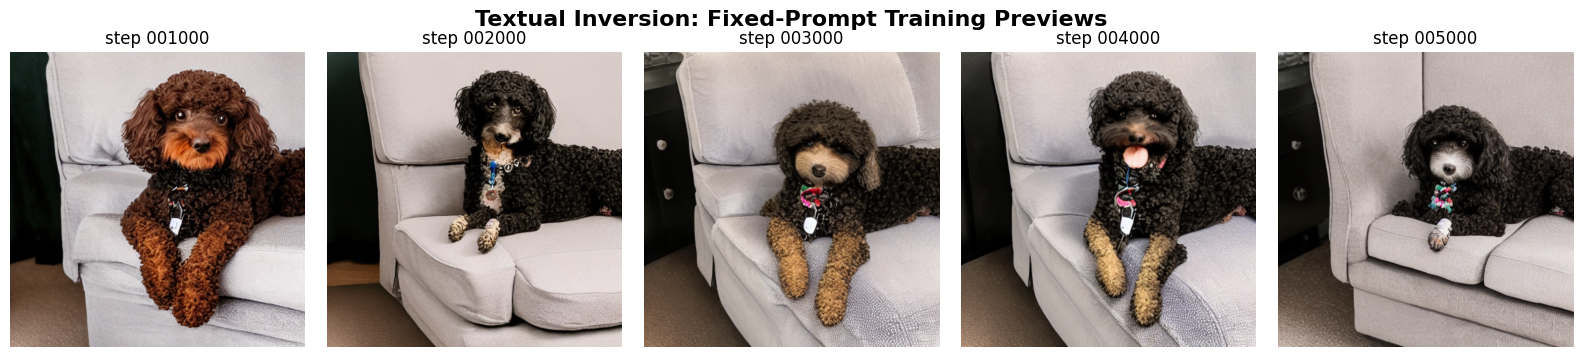

Saved preview timeline to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/textual_inversion_preview_timeline.png


In [ ]:
TEXTUAL_INVERSION_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'textual_inversion'

!python scripts/train.py \
    --method textual_inversion \
    --config configs/textual_inv_cfg.yaml \
    --override processed_images_directory={DRIVE_PROCESSED_IMAGES_DIRECTORY} \
    --override captions_file_path={DRIVE_CAPTIONS_FILE_PATH} \
    --override output_directory={TEXTUAL_INVERSION_OUTPUT_DIRECTORY}

Train DreamBooth

(… library loading + intermediate checkpoints omitted …)
dreambooth: 100% 1200/1200 [28:43<00:00, 1.44s/it, prior=0.1090, subject=0.0477]
DreamBooth done after 1200 steps. UNet saved to /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/dreambooth/latest/unet. Text encoder saved to /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/dreambooth/latest/text_encoder.


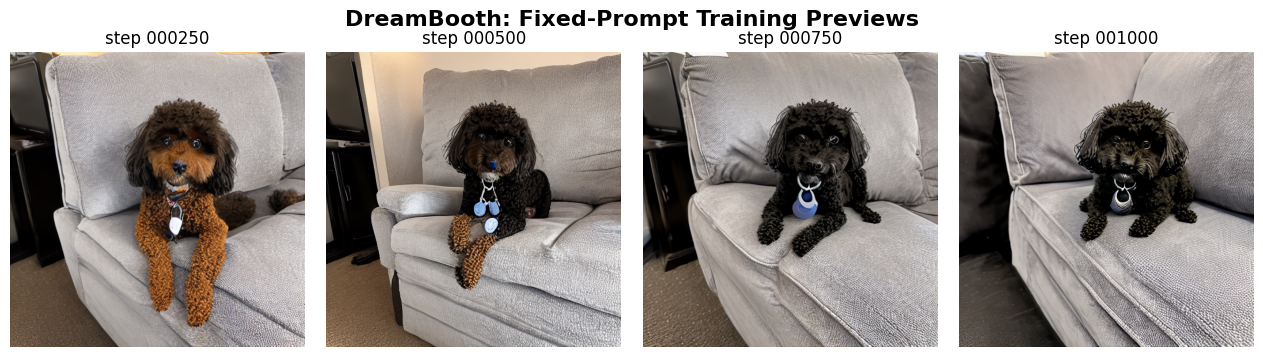

Saved preview timeline to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/dreambooth_preview_timeline.png


In [ ]:
DREAMBOOTH_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'dreambooth'

!python scripts/train.py \
    --method dreambooth \
    --config configs/dreambooth_cfg.yaml \
    --override processed_images_directory={DRIVE_PROCESSED_IMAGES_DIRECTORY} \
    --override captions_file_path={DRIVE_CAPTIONS_FILE_PATH} \
    --override class_prior_images_directory={DRIVE_CLASS_PRIOR_DIRECTORY} \
    --override output_directory={DREAMBOOTH_OUTPUT_DIRECTORY}

CLIP-I and CLIP-T reports

In [ ]:
reference_pil_images = load_pil_images_from_directory(DRIVE_PROCESSED_IMAGES_DIRECTORY)

for method_name, evaluation_settings in EVALUATION_RUNS.items():
    output_dir = evaluation_settings['output_directory']
    subject = evaluation_settings['subject_identifier_phrase']

    generated_pil_images = [
        Image.open(p).convert('RGB')
        for p in sorted(output_dir.glob('gen_*.png'))
    ]
    fully_substituted_prompts = [
        p.format(subject=subject) for p in PRESENTATION_PROMPTS
    ]

    report = compute_clip_similarity_report(
        generated_pil_images=generated_pil_images,
        reference_pil_images=reference_pil_images,
        prompts_used_for_generation=fully_substituted_prompts,
    )
    report_text = format_report_as_human_readable_text(report)
    print(f'\n{"="*80}\n{method_name}')
    print(report_text)
    (output_dir / 'clip_report.txt').write_text(report_text)

(… tqdm / CLIP weight loading omitted — identical to standard HF load …)


textual_inversion
CLIP-I (identity, gen vs refs):   0.7410
CLIP-T (prompt alignment):        0.2730
# generated images considered:    4
# reference images considered:    24

dreambooth
CLIP-I (identity, gen vs refs):   0.8107
CLIP-T (prompt alignment):        0.2357
# generated images considered:    4
# reference images considered:    24


Inference examples Textual Inversion and DreamBooth (stress-test prompts)

Same code run for both methods' final checkpoints. Both output images shown below.

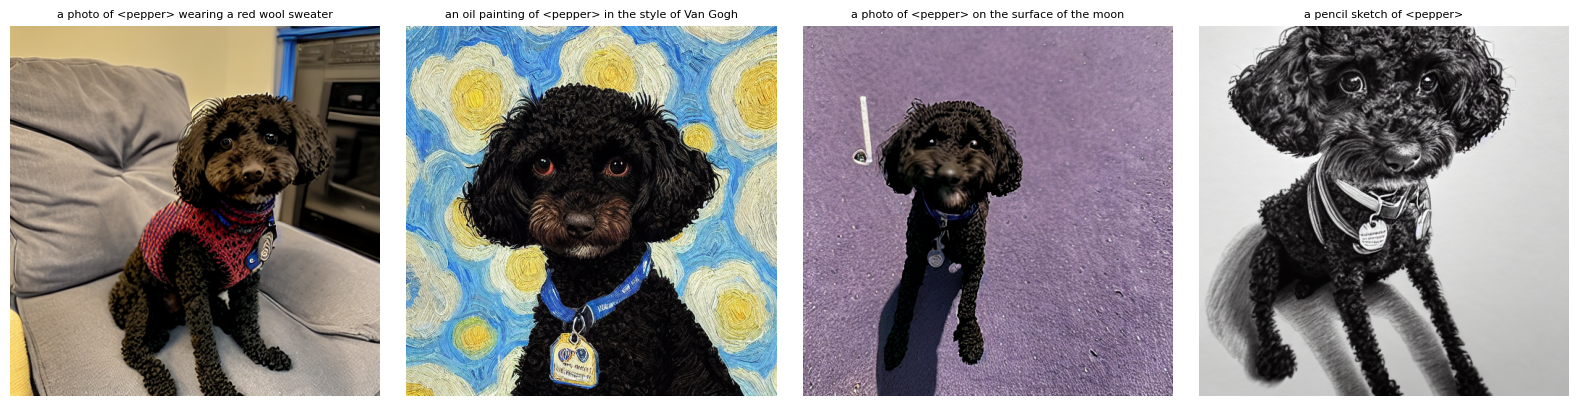

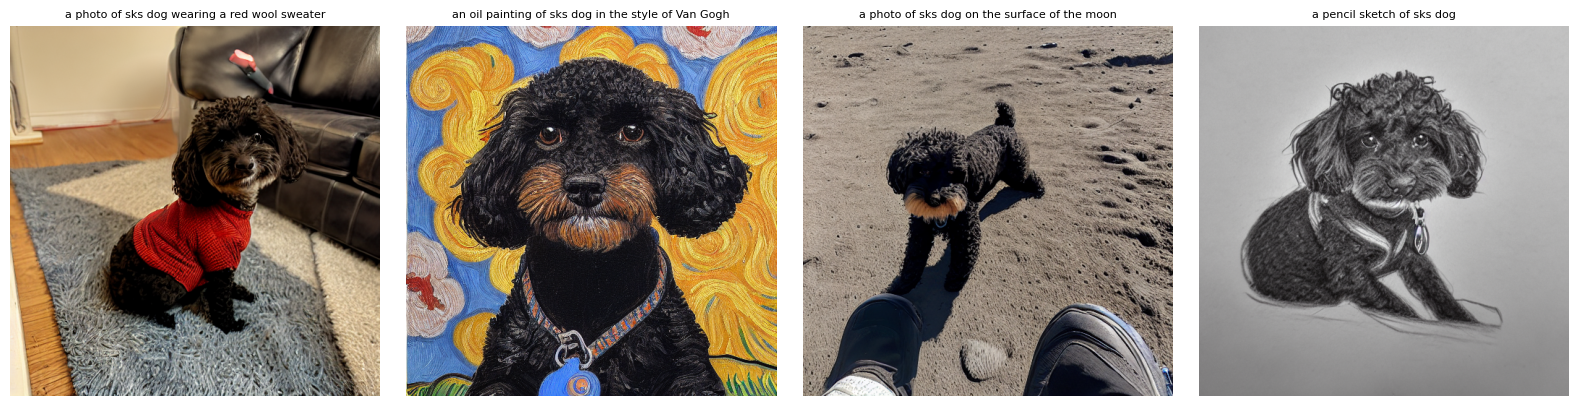

In [ ]:
prompt_templates = [
    'a photo of {subject} wearing a red wool sweater',
    'an oil painting of {subject} in the style of Van Gogh',
    'a photo of {subject} on the surface of the moon',
    'a pencil sketch of {subject}',
]
fully_substituted_prompts = [
    prompt_template.format(subject=subject_phrase_for_prompts)
    for prompt_template in prompt_templates
]

sampling_configuration = SamplingConfiguration(
    number_of_inference_steps=50,
    classifier_free_guidance_scale=7.5,
    random_seed=42,
)

generated_pil_images = sample_images_from_prompts(
    stable_diffusion_components=stable_diffusion_components,
    prompt_texts=fully_substituted_prompts,
    sampling_configuration=sampling_configuration,
)

figure, axes_grid = plt.subplots(
    1,
    len(generated_pil_images),
    figsize=(4 * len(generated_pil_images), 4),
)
if len(generated_pil_images) == 1:
    axes_grid = [axes_grid]
for axis, generated_pil_image, fully_substituted_prompt in zip(
    axes_grid,
    generated_pil_images,
    fully_substituted_prompts,
):
    axis.imshow(generated_pil_image)
    axis.set_title(fully_substituted_prompt, fontsize=8)
    axis.axis('off')
plt.tight_layout()
plt.show()